# AI-рекомендации: анализ A/B-эксперимента

Ноутбук последовательно объясняет результаты. Расчёты находятся в небольших модулях `src/`. Изменения настроек применяются после повторного выполнения запуска.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image, Markdown
from src.config import Config
from src.pipeline import run_analysis

# Рабочая папка — корень репозитория.
ROOT = Path.cwd()
assert (ROOT / 'users.csv').exists(), 'Открой ноутбук из корня проекта'
config = Config()
display(config.serializable())

{'data_dir': '/workspaces/Data_analysis_1',
 'output_dir': '/workspaces/Data_analysis_1/reports',
 'experiment_name': 'ai_recommendations_homepage',
 'start': '2026-07-01',
 'end': '2026-07-30',
 'alpha': 0.05,
 'power': 0.8,
 'expected_test_share': 0.5,
 'srm_alpha': 0.0005,
 'seed': 2026,
 'bootstrap_repeats': 2000,
 'permutation_repeats': 1999,
 'followup_days': 30,
 'observation_end': None,
 'assume_complete_event_log': True,
 'minimum_gmv_lift': None,
 'max_return_increase_pp': None,
 'max_support_increase_pp': None,
 'support_cost_rub': None,
 'ai_cost_per_impression_rub': None,
 'assume_full_refund': False}

## 1. Полный воспроизводимый запуск

`run_analysis` вызывает загрузку, аудит, очистку, статистику и графики. Исходные CSV только читаются; результаты записываются в `reports/`. Дата полной выгрузки не задана, поэтому поздние последствия не объявляются полным follow-up.

In [2]:
# Около минуты, зависит от компьютера и числа повторений.
result = run_analysis(config)
tables = result['tables']

1/8 Загрузка и аудит CSV


2/8 Выборки и пользовательская витрина


3/8 Основные метрики и множественные поправки
4/8 Bootstrap и проверки распределений


5/8 Сегменты, взаимодействия и каталог


6/8 Диагностика, чувствительность и экономика


7/8 Графики и отчёт


8/8 Проверка исходников и метаданные воспроизводимости
Готово: /workspaces/Data_analysis_1/reports/analysis_report.md


## 2. Качество данных и назначения

Сначала размеры и ошибки связей. Ненулевые предупреждения нужно интерпретировать, а ошибки останавливают запуск. SRM назначенных пользователей отделён от доли активных, которую могло изменить воздействие.

In [3]:
display(tables['profile'])
display(tables['quality_checks'].query('issues > 0'))
display(tables['date_bounds'])
display(tables['srm'])

,table,rows,columns,expected_rows,exact_duplicate_rows
0,users,50000,8,50000.0,0
1,experiment_assignments,50300,6,NaN,0
2,sessions,164739,9,164739.0,0
3,impressions,1066434,9,1066434.0,0
4,clicks,91266,7,91266.0,0
5,orders,7407,14,7407.0,0
6,products,4500,8,4500.0,0
7,sellers,700,5,700.0,0
8,support_tickets,337,7,337.0,0
9,premium_subscriptions,9127,6,9127.0,0


,check,issues,severity,note
91,missing delivery fee,303,warning,
92,flagged duplicate impressions,3193,warning,Флаг не доказывает наличие восстановимого ориг...
94,returns after experiment,300,warning,
95,tickets after experiment,27,warning,


,table,field,min,max
0,users,registration_date,2017-05-18 00:00:00,2026-07-01 00:00:00
1,experiment_assignments,assignment_date,2026-07-01 00:00:00,2026-07-06 00:00:00
2,sessions,session_date,2026-07-01 00:00:00,2026-07-30 00:00:00
3,impressions,event_time,2026-07-01 08:00:00,2026-07-30 22:59:56
4,clicks,event_time,2026-07-01 08:00:02,2026-07-30 22:59:55
5,orders,order_date,2026-07-01 00:00:00,2026-07-30 00:00:00
6,orders,return_date,2026-07-05 00:00:00,2026-09-04 00:00:00
7,products,created_date,2021-01-01 00:00:00,2026-03-14 00:00:00
8,sellers,joined_date,2020-01-01 00:00:00,2026-01-08 00:00:00
9,support_tickets,ticket_date,2026-07-02 00:00:00,2026-08-03 00:00:00


,population,count_field,control,test,chi2,p_value,srm_flag,note
0,include_bots,users,24674,25026,2.493038,0.114351,False,Ожидаемая доля test 50.0% — допущение
1,include_bots,active_users,24674,25026,2.493038,0.114351,False,Активность — исход воздействия; эта строка не ...
2,initial_assignment_itt,users,24613,24987,2.820081,0.093092,False,Ожидаемая доля test 50.0% — допущение
3,initial_assignment_itt,active_users,24613,24987,2.820081,0.093092,False,Активность — исход воздействия; эта строка не ...
4,initial_unique_assignment,users,24815,25185,2.738000,0.097987,False,Ожидаемая доля test 50.0% — допущение
5,initial_unique_assignment,active_users,24815,25185,2.738000,0.097987,False,Активность — исход воздействия; эта строка не ...
6,main,users,24473,24828,2.556236,0.109860,False,Ожидаемая доля test 50.0% — допущение
7,main,active_users,24473,24828,2.556236,0.109860,False,Активность — исход воздействия; эта строка не ...


## 3. Что исключено

Основная выборка не содержит конфликтующих назначений и ботов. Это анализ очищенной аудитории, не полный ITT. Флаги дублей не удаляют связанные покупки; CTR без них проверяется отдельно.

In [4]:
display(tables['cleaning_log'])
display(tables['duplicate_impact'])
display(tables['bot_activity'])
display(tables['user_metrics'].head())

,rule,group,users_kept,users_excluded,sessions_excluded,impressions_excluded,orders_excluded
0,initial_unique_assignment,control,24815,0,0,0,0
1,initial_unique_assignment,test,25185,0,0,0,0
2,exclude_conflicts,control,24674,141,456,2940,19
3,exclude_conflicts,test,25026,159,565,3675,25
4,exclude_conflicts_and_bots,control,24473,342,3667,23728,38
5,exclude_conflicts_and_bots,test,24828,357,3770,24500,42
6,initial_assignment_sensitivity,control,24613,202,3231,20921,19
7,initial_assignment_sensitivity,test,24987,198,3205,20825,17


,flagged_impressions,linked_clicks,linked_orders,natural_key_duplicates,policy
0,3193,310,25,0,keep_unique_events; flag-excluded CTR is sensi...


,is_bot_candidate,users,impressions_mean,impressions_p99,impressions_max,sessions_mean
0,0,49600,20.659032,57.00,100,3.191593
1,1,400,104.365000,173.01,223,16.090000


,user_id,registration_date,region,device,age_group,traffic_source,is_premium,is_bot_candidate,group,first_assignment,...,tickets_window,new_premium_records,buyer,reached,clicker,return_user_window,return_user_observed,support_user_window,support_user_observed,new_premium_user
0,u_000001,2026-04-29,Volga,android,18-24,paid_ads,0,0,control,2026-07-01,...,0.0,0.0,0,1,1,0,0,0,0,0
1,u_000002,2026-02-25,Central Russia,android,35-44,direct,0,0,test,2026-07-01,...,0.0,0.0,0,1,0,0,0,0,0,0
2,u_000003,2026-04-01,Moscow,web,18-24,push,1,0,control,2026-07-01,...,0.0,0.0,0,1,1,0,0,0,0,0
3,u_000004,2026-03-08,Ural,ios,25-34,paid_ads,0,0,control,2026-07-01,...,0.0,0.0,0,1,0,0,0,0,0,0
4,u_000005,2025-07-28,Central Russia,android,18-24,organic,1,0,test,2026-07-01,...,0.0,0.0,0,1,1,0,0,0,0,0


## 4. Определения и эффекты

Одна строка витрины — пользователь. Для CTR и среднего чека оценивается отношение сумм с пользовательской ковариацией. Доли в CSV хранятся от 0 до 1: разница 0.01 равна одному процентному пункту.

In [5]:
display(tables['metric_definitions'])
columns = ['metric', 'control', 'test', 'effect', 'relative_effect_pct', 'ci_low', 'ci_high', 'method', 'p_adjusted']
display(tables['metrics'][columns])

,name,label,kind,numerator,denominator,family,unit,window
0,gmv_user,GMV на пользователя,mean,gmv,None,confirmatory,руб./польз.,30 дней эксперимента
1,margin_user,Записанная валовая маржа на пользователя,mean,margin,None,confirmatory,руб./польз.,Заказы эксперимента; маржа уже учитывает запис...
2,return_user_window,Доля пользователей с возвратом в эксперименте,binary,return_user_window,None,confirmatory,доля,30 дней эксперимента
3,support_user_window,Доля пользователей с обращением в эксперименте,binary,support_user_window,None,confirmatory,доля,30 дней эксперимента
4,buyer_conversion,Конверсия пользователя в покупку,binary,buyer,None,secondary,доля,30 дней эксперимента
5,reach,Охват рекомендациями,binary,reached,None,secondary,доля,30 дней эксперимента
6,ctr,CTR уникальных записей показов,ratio,clicks,impressions,secondary,доля,30 дней эксперимента
7,ctr_unflagged,CTR без помеченных показов,ratio,clicks_unflagged,impressions_unflagged,sensitivity,доля,30 дней эксперимента
8,orders_user,Заказы на пользователя,mean,orders,None,secondary,на пользователя,30 дней эксперимента
9,clicks_user,Клики на пользователя,mean,clicks,None,secondary,на пользователя,30 дней эксперимента


,metric,control,test,effect,relative_effect_pct,ci_low,ci_high,method,p_adjusted
0,gmv_user,211.146611,286.414613,75.268002,35.647270,59.146924,91.389080,Welch t-test,2.338518e-19
1,margin_user,35.114140,46.323435,11.209295,31.922452,8.626254,13.792336,Welch t-test,5.570854e-17
2,return_user_window,0.002493,0.003947,0.001455,58.358622,0.000454,0.002477,Two-proportion Z-test; Newcombe CI,4.397224e-03
3,support_user_window,0.004822,0.007612,0.002791,57.879328,0.001407,0.004196,Two-proportion Z-test; Newcombe CI,1.640526e-04
4,buyer_conversion,0.118089,0.151724,0.033635,28.482285,0.027612,0.039657,Two-proportion Z-test; Newcombe CI,3.248285e-27
5,reach,1.000000,1.000000,0.000000,0.000000,-0.000155,0.000157,Fisher exact; Newcombe CI,1.000000e+00
6,ctr,0.073060,0.090246,0.017186,23.522572,0.016117,0.018255,User-cluster delta method,9.648796e-217
7,ctr_unflagged,0.073030,0.090225,0.017196,23.546118,0.016125,0.018266,User-cluster delta method,1.676846e-217
8,orders_user,0.126956,0.169969,0.043013,33.880298,0.036055,0.049971,Welch t-test,4.836173e-33
9,clicks_user,1.510890,1.861406,0.350517,23.199374,0.322664,0.378370,Welch t-test,1.254689e-132


## 5. Устойчивость и дополнительные критерии

Bootstrap пересэмплирует пользователей. Манна–Уитни проверяет ранговые различия, не средние. KS использует перестановки из-за нулей и совпадений. MDE — приближённая чувствительность, не доказательство наблюдаемой мощности.

In [6]:
display(tables['bootstrap'])
display(tables['distribution_tests'])
display(tables['metrics'][['metric', 'mde_absolute_approx', 'mde_relative_pct_approx', 'mde_note']])

,metric,ci_low,ci_high,repeats,valid_repeats,seed,method
0,gmv_user,59.463608,91.007304,2000,2000,2026,"Independent user bootstrap, percentile CI; no ..."
1,margin_user,8.739600,13.866087,2000,2000,2026,"Independent user bootstrap, percentile CI; no ..."
2,ctr,0.016165,0.018241,2000,2000,2026,"Independent user bootstrap, percentile CI; no ..."
3,aov,-55.377497,97.660445,2000,2000,2026,"Independent user bootstrap, percentile CI; no ..."
4,return_rate_observed,0.001688,0.023867,2000,2000,2026,"Independent user bootstrap, percentile CI; no ..."
5,tickets_per_order_observed,-0.004388,0.014911,2000,2000,2026,"Independent user bootstrap, percentile CI; no ..."


,metric,method,statistic,p_value,rank_biserial,family,repeats,p_adjusted,correction,significant_adjusted
0,gmv,Mann–Whitney with tie correction,3.142516e+08,9.191634e-29,0.034376,distribution,NaN,3.676654e-28,fdr_bh,True
1,gmv,KS statistic; user-label permutations (zeros/t...,3.372210e-02,5.000000e-04,NaN,distribution,1999.0,5.000000e-04,fdr_bh,True
2,margin,Mann–Whitney with tie correction,3.121132e+08,8.802844e-19,0.027338,distribution,NaN,1.760569e-18,fdr_bh,True
3,margin,KS statistic; user-label permutations (zeros/t...,3.021924e-02,5.000000e-04,NaN,distribution,1999.0,5.000000e-04,fdr_bh,True


,metric,mde_absolute_approx,mde_relative_pct_approx,mde_note
0,gmv_user,23.042996,10.913268,Normal approximation; rare events require dedi...
1,margin_user,3.692123,10.514633,Normal approximation; rare events require dedi...
2,return_user_window,0.001428,57.306502,Normal approximation; rare events require dedi...
3,support_user_window,0.001982,41.099950,Normal approximation; rare events require dedi...
4,buyer_conversion,0.008607,7.288914,Normal approximation; rare events require dedi...
5,reach,NaN,NaN,Degenerate observed rate: cannot estimate MDE ...
6,ctr,0.001528,2.091447,Normal approximation; rare events require dedi...
7,ctr_unflagged,0.001530,2.095561,Normal approximation; rare events require dedi...
8,orders_user,0.009946,7.833833,Normal approximation; rare events require dedi...
9,clicks_user,0.039813,2.635057,Normal approximation; rare events require dedi...


## 6. Сегменты

Сравнение значимого и незначимого сегментов не доказывает неоднородность. Для этого нужна совместная проверка взаимодействия; при редких событиях ненадёжный Wald-тест пропускается. Категории оцениваются на всей назначенной аудитории, не только среди покупателей категории.

In [7]:
display(tables['baseline_balance'])
display(tables['interactions'])
display(tables['segment_effects'][['segment', 'level', 'metric', 'n_control', 'n_test', 'effect', 'ci_low', 'ci_high', 'p_adjusted']])
display(tables['category_effects'])

,field,chi2,p_value,df,min_expected_count,max_abs_smd,family,p_adjusted,correction,significant_adjusted
0,device,3.774947,0.151454,2,3724.983104,0.016981,balance,0.588516,fdr_bh,False
1,region,5.257938,0.628518,7,713.822722,0.019945,balance,0.674998,fdr_bh,False
2,is_premium,0.706300,0.400675,1,4045.657289,0.007570,balance,0.674998,fdr_bh,False
3,tenure,1.531592,0.674998,3,2965.491613,0.011065,balance,0.674998,fdr_bh,False
4,age_group,2.352877,0.671159,4,1976.167076,0.009280,balance,0.674998,fdr_bh,False
5,traffic_source,7.345719,0.196172,5,1716.053650,0.016983,balance,0.588516,fdr_bh,False


,segment,metric,statistic,df,p_value,family,method,p_adjusted,correction,significant_adjusted
0,device,gmv_user,19.518742,2.0,0.000058,interaction,"Asymptotic Wald interaction, independent strata",0.000809,fdr_bh,True
1,device,margin_user,11.171237,2.0,0.003751,interaction,"Asymptotic Wald interaction, independent strata",0.026260,fdr_bh,True
2,device,return_user_window,7.478513,2.0,0.023772,interaction,"Asymptotic Wald interaction, independent strata",0.055467,fdr_bh,False
3,device,support_user_window,8.942371,2.0,0.011434,interaction,"Asymptotic Wald interaction, independent strata",0.038412,fdr_bh,True
4,region,gmv_user,4.645472,7.0,0.703137,interaction,"Asymptotic Wald interaction, independent strata",0.703137,fdr_bh,False
5,region,margin_user,7.901966,7.0,0.341318,interaction,"Asymptotic Wald interaction, independent strata",0.420604,fdr_bh,False
6,region,return_user_window,NaN,NaN,NaN,interaction,Not tested: rare events in at least one level;...,NaN,,False
7,region,support_user_window,NaN,NaN,NaN,interaction,Not tested: rare events in at least one level;...,NaN,,False
8,is_premium,gmv_user,6.074017,1.0,0.013718,interaction,"Asymptotic Wald interaction, independent strata",0.038412,fdr_bh,True
9,is_premium,margin_user,6.500232,1.0,0.010786,interaction,"Asymptotic Wald interaction, independent strata",0.038412,fdr_bh,True


,segment,level,metric,n_control,n_test,effect,ci_low,ci_high,p_adjusted
0,device,android,gmv_user,14050,14462,104.416630,83.090224,125.743036,6.082473e-20
1,device,android,margin_user,14050,14462,14.927729,11.514415,18.341042,3.634878e-16
2,device,android,return_user_window,14050,14462,0.002003,0.000633,0.003418,9.640031e-03
3,device,android,support_user_window,14050,14462,0.004302,0.002450,0.006206,4.390813e-05
4,device,ios,gmv_user,6677,6608,48.131713,17.295279,78.968146,6.293592e-03
...,...,...,...,...,...,...,...,...,...
63,tenure,91–365,support_user_window,11472,11710,0.003238,0.001228,0.005300,5.155856e-03
64,tenure,>365,gmv_user,5247,5339,50.050918,16.151987,83.949849,9.594200e-03
65,tenure,>365,margin_user,5247,5339,6.770836,1.275882,12.265791,2.610199e-02
66,tenure,>365,return_user_window,5247,5339,0.001265,-0.000995,0.003601,3.119649e-01


,category,metric,control,test,effect,se,ci_low,ci_high,p_value,method,n_control,n_test,family,p_adjusted,correction,significant_adjusted
0,Auto,gmv,17.590528,23.665942,6.075413,2.291278,1.584479,10.566347,8.015182e-03,Welch t-test,24473,24828,category_exploration,1.233105e-02,fdr_bh,True
1,Auto,margin,2.953237,3.768111,0.814874,0.392581,0.045411,1.584338,3.792825e-02,Welch t-test,24473,24828,category_exploration,4.077095e-02,fdr_bh,True
2,Beauty,gmv,12.863074,16.660947,3.797874,1.213717,1.418973,6.176775,1.754308e-03,Welch t-test,24473,24828,category_exploration,5.847694e-03,fdr_bh,True
3,Beauty,margin,3.545115,4.529725,0.984609,0.338373,0.321395,1.647824,3.617810e-03,Welch t-test,24473,24828,category_exploration,7.235619e-03,fdr_bh,True
4,Books,gmv,2.462183,3.459965,0.997782,0.327339,0.356192,1.639372,2.303762e-03,Welch t-test,24473,24828,category_exploration,6.582176e-03,fdr_bh,True
5,Books,margin,0.420469,0.596155,0.175686,0.059898,0.058285,0.293086,3.357730e-03,Welch t-test,24473,24828,category_exploration,7.235619e-03,fdr_bh,True
6,Electronics,gmv,73.169493,104.099766,30.930273,6.332153,18.519171,43.341376,1.039499e-06,Welch t-test,24473,24828,category_exploration,1.039499e-05,fdr_bh,True
7,Electronics,margin,8.104535,11.418527,3.313992,0.757861,1.828574,4.799409,1.229045e-05,Welch t-test,24473,24828,category_exploration,8.193631e-05,fdr_bh,True
8,FMCG,gmv,5.139460,6.930683,1.791223,0.567387,0.679136,2.903311,1.595209e-03,Welch t-test,24473,24828,category_exploration,5.847694e-03,fdr_bh,True
9,FMCG,margin,0.697260,0.929442,0.232182,0.079234,0.076883,0.387481,3.387536e-03,Welch t-test,24473,24828,category_exploration,7.235619e-03,fdr_bh,True


## 7. Возвраты, поддержка и экономика

Оконные события отделены от записанных последующих событий. Маржа уже учитывает возвраты: повторного вычитания нет. Доставка не объявляется расходом без определения поля. Затраты поддержки и AI в сценариях предполагаются дополнительными к марже.

In [8]:
display(tables['return_cohorts'].head(10))
display(tables['support_reasons'])
display(tables['delivery_missing'])
display(tables['delivery_scenarios'])
display(tables['economic_scenarios'][['support_cost_rub', 'ai_cost_per_impression_rub', 'effect', 'ci_low', 'ci_high']])
display(tables['break_even_costs'])

,group,order_date,orders,returns_window,returns_observed,observed_return_rate
0,control,2026-07-01,110,4,8,0.072727
1,control,2026-07-02,112,5,7,0.062500
2,control,2026-07-03,106,4,5,0.047170
3,control,2026-07-04,106,2,4,0.037736
4,control,2026-07-05,108,5,6,0.055556
5,control,2026-07-06,113,4,6,0.053097
6,control,2026-07-07,109,7,9,0.082569
7,control,2026-07-08,94,1,4,0.042553
8,control,2026-07-09,97,2,5,0.051546
9,control,2026-07-10,118,3,5,0.042373


,group,reason,tickets,sentiment,resolved_24h_share,interpretation
0,control,delivery_delay,34,0.142882,0.794118,Описательно среди обратившихся; состав зависит...
1,control,payment_issue,11,-0.244909,0.818182,Описательно среди обратившихся; состав зависит...
2,control,product_quality,46,0.189109,0.695652,Описательно среди обратившихся; состав зависит...
3,control,recommendation_quality,12,0.071000,0.750000,Описательно среди обратившихся; состав зависит...
4,control,return_request,15,0.207333,0.733333,Описательно среди обратившихся; состав зависит...
5,control,wrong_item,15,-0.263533,0.533333,Описательно среди обратившихся; состав зависит...
6,test,delivery_delay,42,0.115238,0.785714,Описательно среди обратившихся; состав зависит...
7,test,payment_issue,22,-0.288682,0.681818,Описательно среди обратившихся; состав зависит...
8,test,product_quality,69,0.155971,0.739130,Описательно среди обратившихся; состав зависит...
9,test,recommendation_quality,11,-0.167091,1.000000,Описательно среди обратившихся; состав зависит...


,group,category,orders,missing_fee,median_fee,missing_share
0,control,Auto,173,4,177.0,0.023121
1,control,Beauty,389,14,176.0,0.035990
2,control,Books,176,7,179.0,0.039773
3,control,Electronics,434,28,69.0,0.064516
4,control,FMCG,290,10,183.5,0.034483
5,control,Fashion,502,15,181.0,0.029880
6,control,Home,448,18,171.0,0.040179
7,control,Kids,263,11,171.0,0.041825
8,control,Pet,205,11,170.0,0.053659
9,control,Sports,227,4,181.0,0.017621


,group,missing_orders,observed_fee_sum,zero_fill_sum,pooled_category_median_fill_sum,note
0,control,122,458237.0,458237.0,476629.5,Сумма платежей доставки; знак влияния на прибы...
1,test,178,599180.0,599180.0,627794.0,Сумма платежей доставки; знак влияния на прибы...


,support_cost_rub,ai_cost_per_impression_rub,effect,ci_low,ci_high
0,0.0,0.00,11.209295,8.626254,13.792336
1,0.0,0.01,11.003035,8.420205,13.585865
2,0.0,0.05,10.177995,7.595998,12.759993
3,0.0,0.10,9.146696,6.565720,11.727672
4,0.0,0.50,0.896301,-1.677331,3.469934
5,0.0,1.00,-9.416692,-11.983215,-6.850169
6,100.0,0.00,10.939153,8.371277,13.507030
7,100.0,0.01,10.732893,8.165225,13.300562
8,100.0,0.05,9.907854,7.341009,12.474699
9,100.0,0.10,8.876555,6.310718,11.442391


,support_cost_rub,ai_break_even_rub_per_impression,ci_low,ci_high,note
0,0.0,0.543455,0.418716,0.668194,Сценарная граница записанной маржи; дополнител...
1,100.0,0.530358,0.406337,0.654378,Сценарная граница записанной маржи; дополнител...
2,300.0,0.504164,0.380386,0.627942,Сценарная граница записанной маржи; дополнител...
3,500.0,0.477969,0.352840,0.603098,Сценарная граница записанной маржи; дополнител...


## 8. Чувствительность правил

Проверь, насколько результаты меняются с ботами и по первичному назначению. Отсечка хвоста — отдельная гипотеза; основной денежный эффект рассчитан на исходных значениях.

In [9]:
selected = tables['sensitivity'].query("metric in ['gmv_user', 'margin_user', 'ctr', 'ctr_unflagged']")
display(selected[['sample', 'metric', 'effect', 'ci_low', 'ci_high', 'p_adjusted']])

,sample,metric,effect,ci_low,ci_high,p_adjusted
0,main,gmv_user,75.268002,59.146924,91.389080,2.338518e-19
1,main,margin_user,11.209295,8.626254,13.792336,5.570854e-17
6,main,ctr,0.017186,0.016117,0.018255,9.648796e-217
7,main,ctr_unflagged,0.017196,0.016125,0.018266,1.676846e-217
20,include_bots,gmv_user,74.849206,58.832999,90.865413,2.157798e-19
21,include_bots,margin_user,11.107565,8.538942,13.676188,7.200272e-17
26,include_bots,ctr,0.018218,0.016904,0.019532,2.382972e-161
27,include_bots,ctr_unflagged,0.018234,0.016919,0.019549,1.248719e-162
40,initial_assignment_itt,gmv_user,74.420586,58.336004,90.505167,4.994719e-19
41,initial_assignment_itt,margin_user,11.128149,8.553565,13.702732,7.448785e-17


## 9. Графики и решение

Интервалы на графиках индивидуальные, до множественных поправок. Следи за единицами и знаменателями. Дневную динамику нельзя использовать для выбора удачного дня остановки.

**01_population**

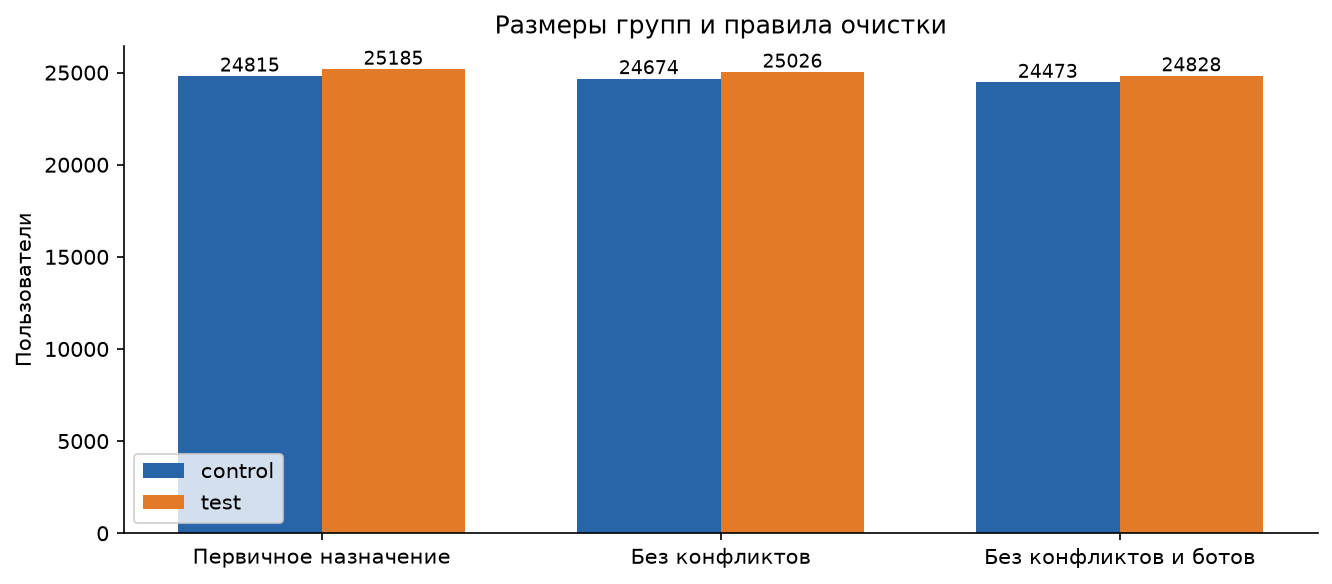

**02_funnel**

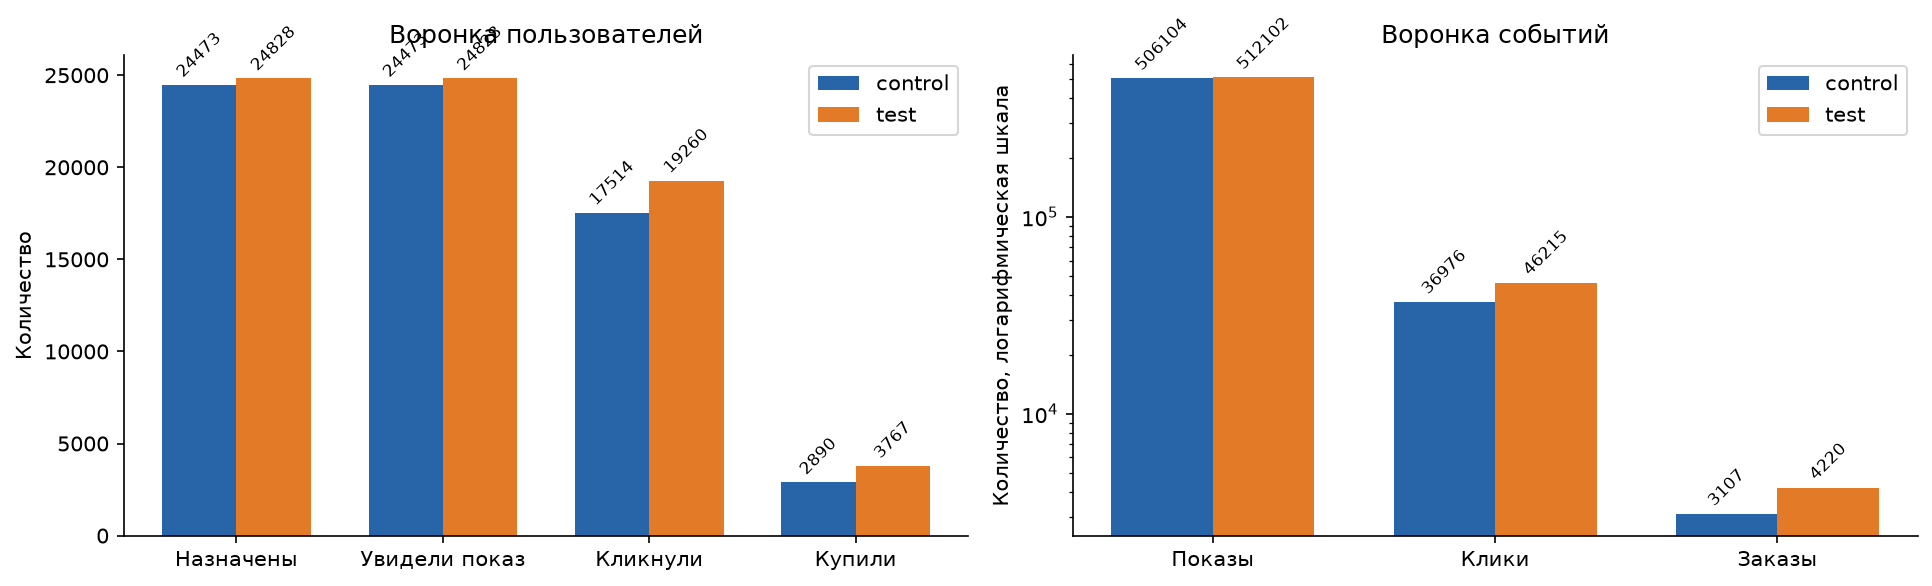

**03_daily**

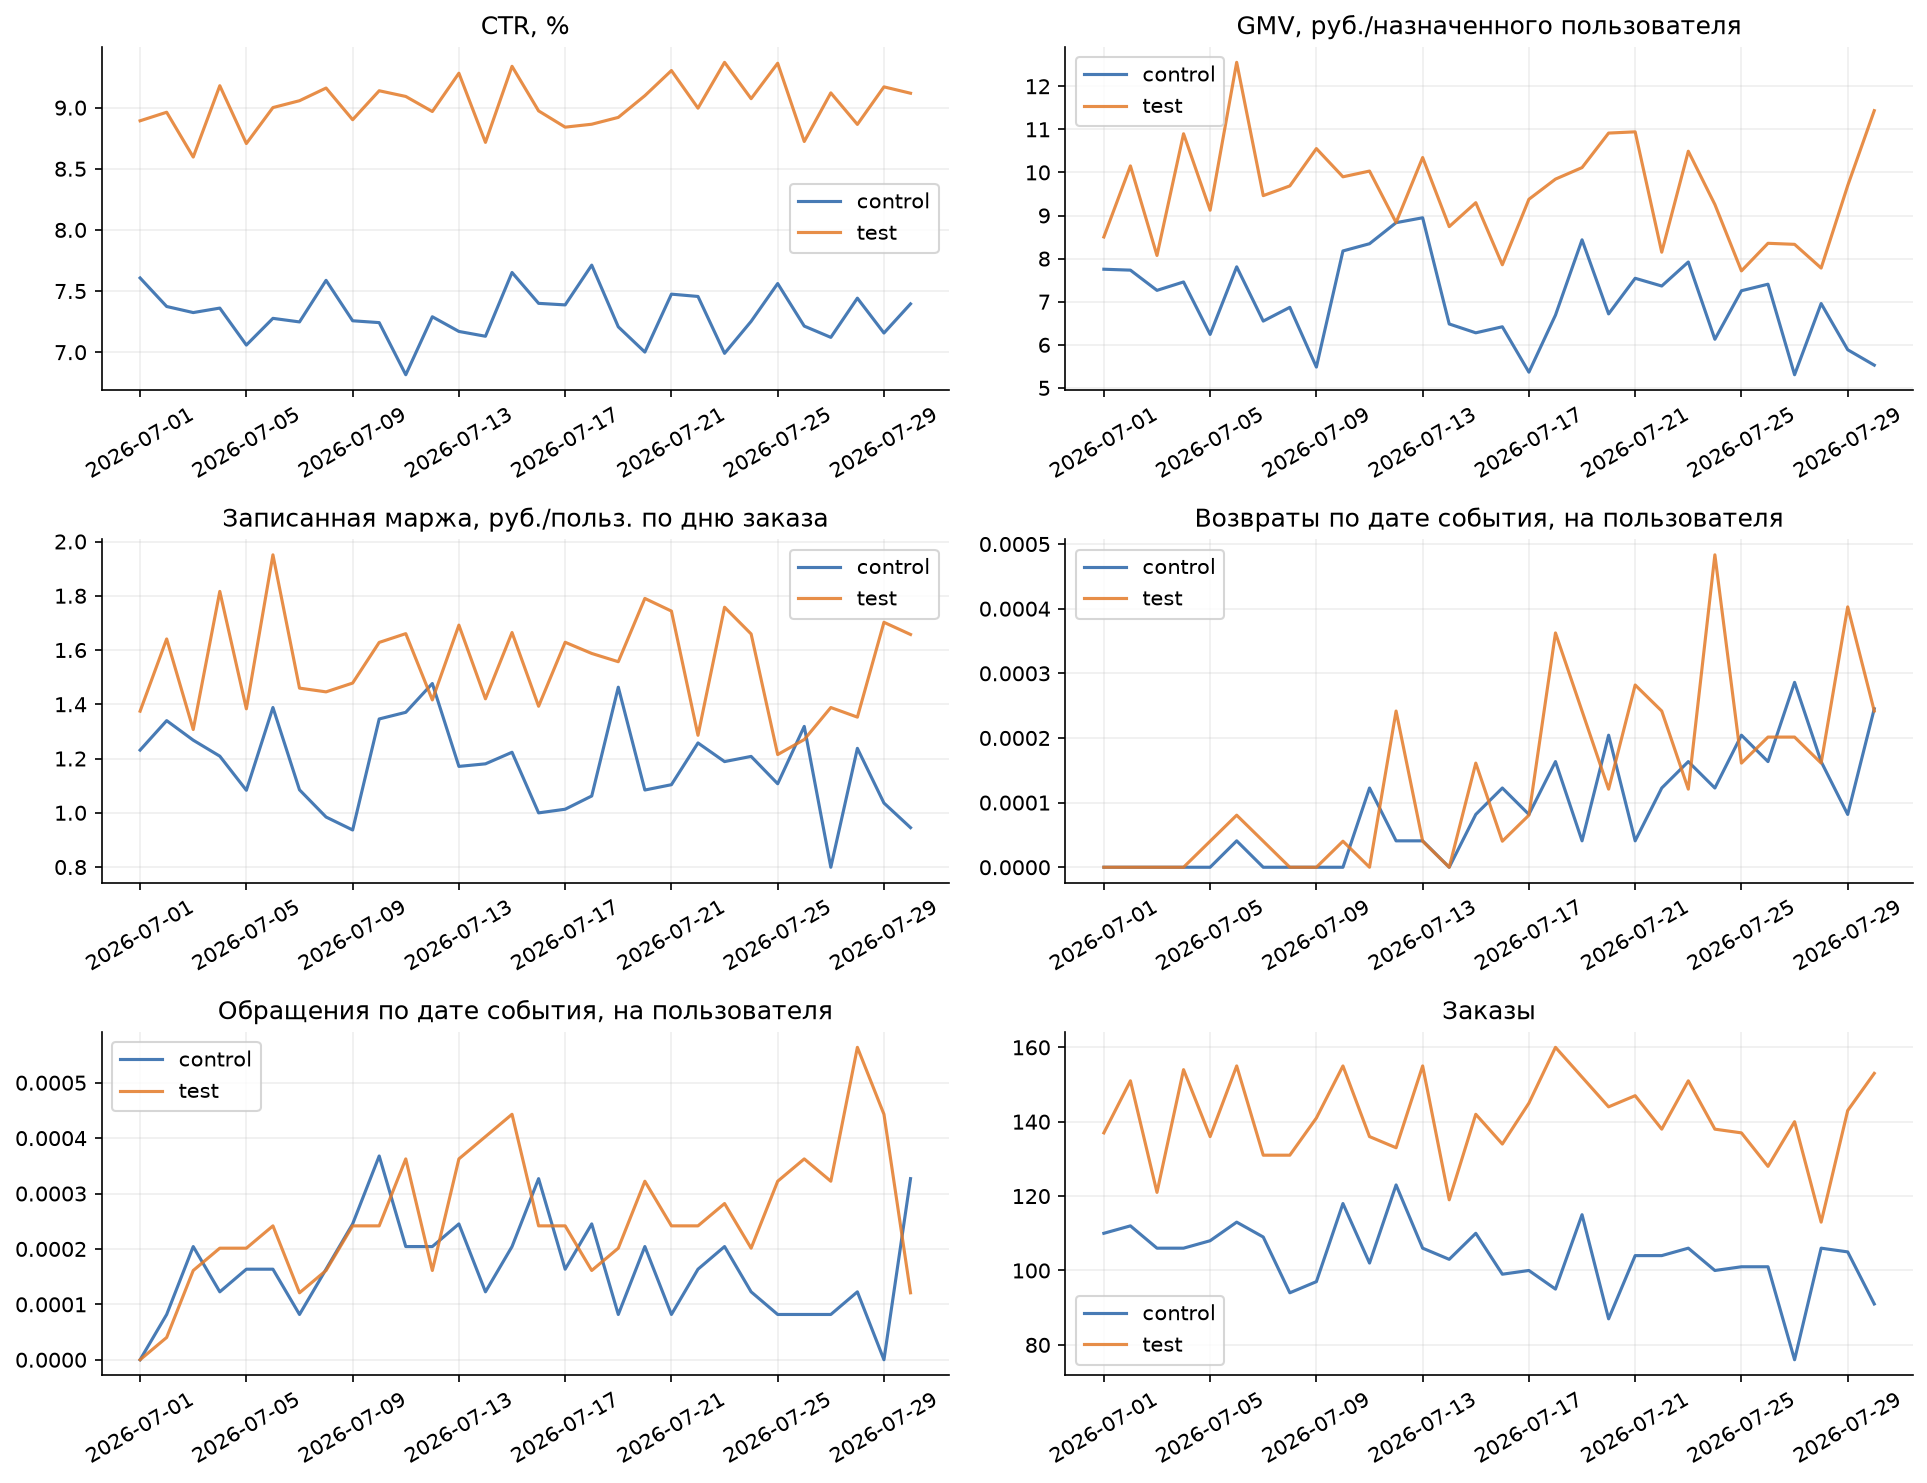

**04_distributions**

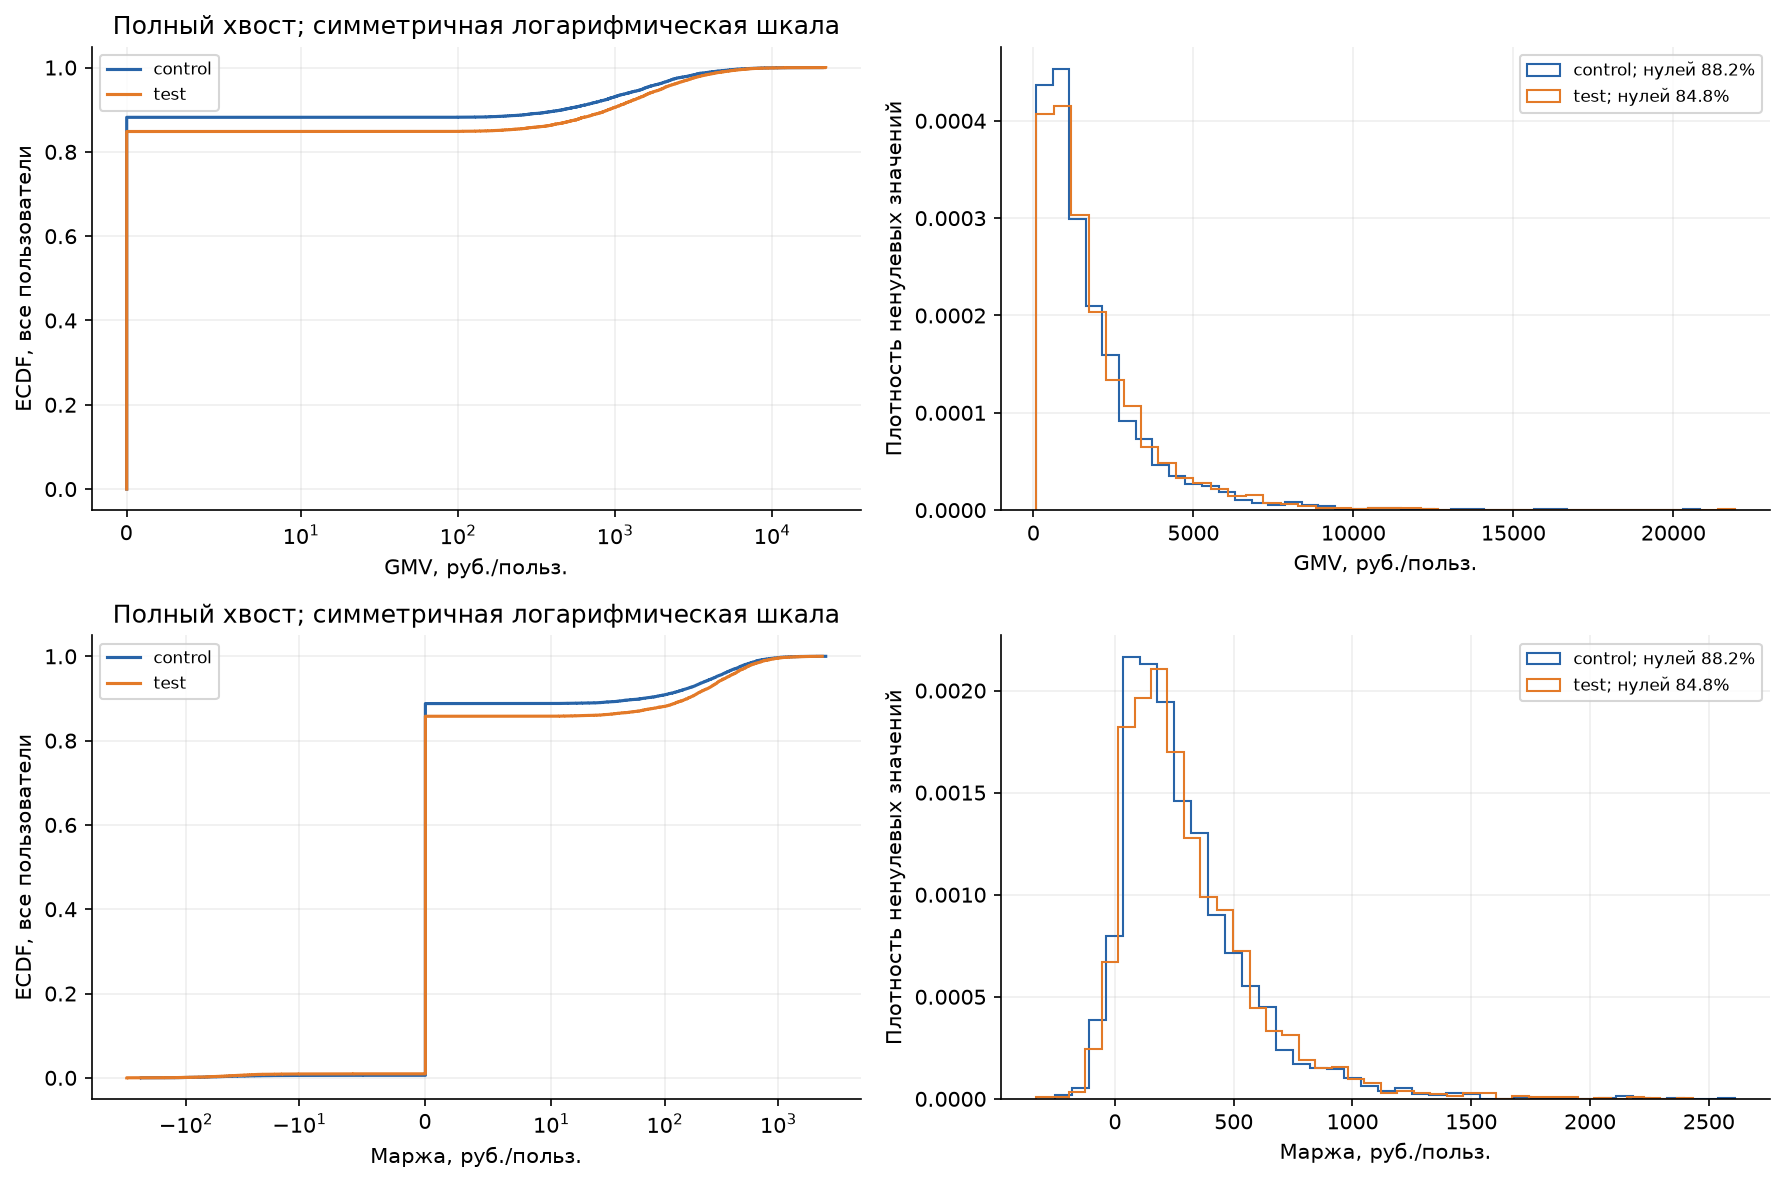

**05_effects**

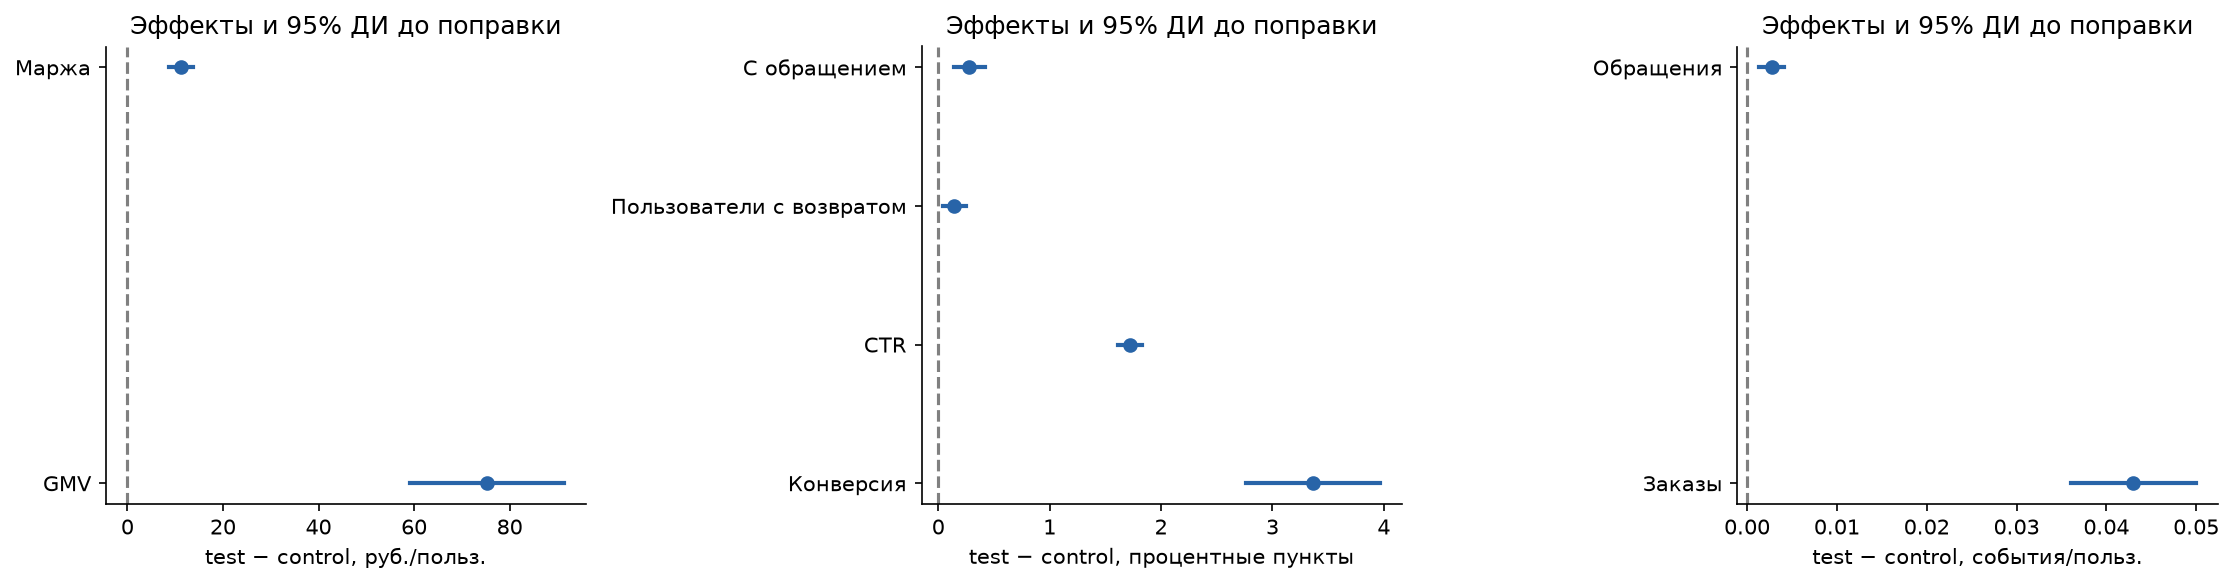

**06_segments**

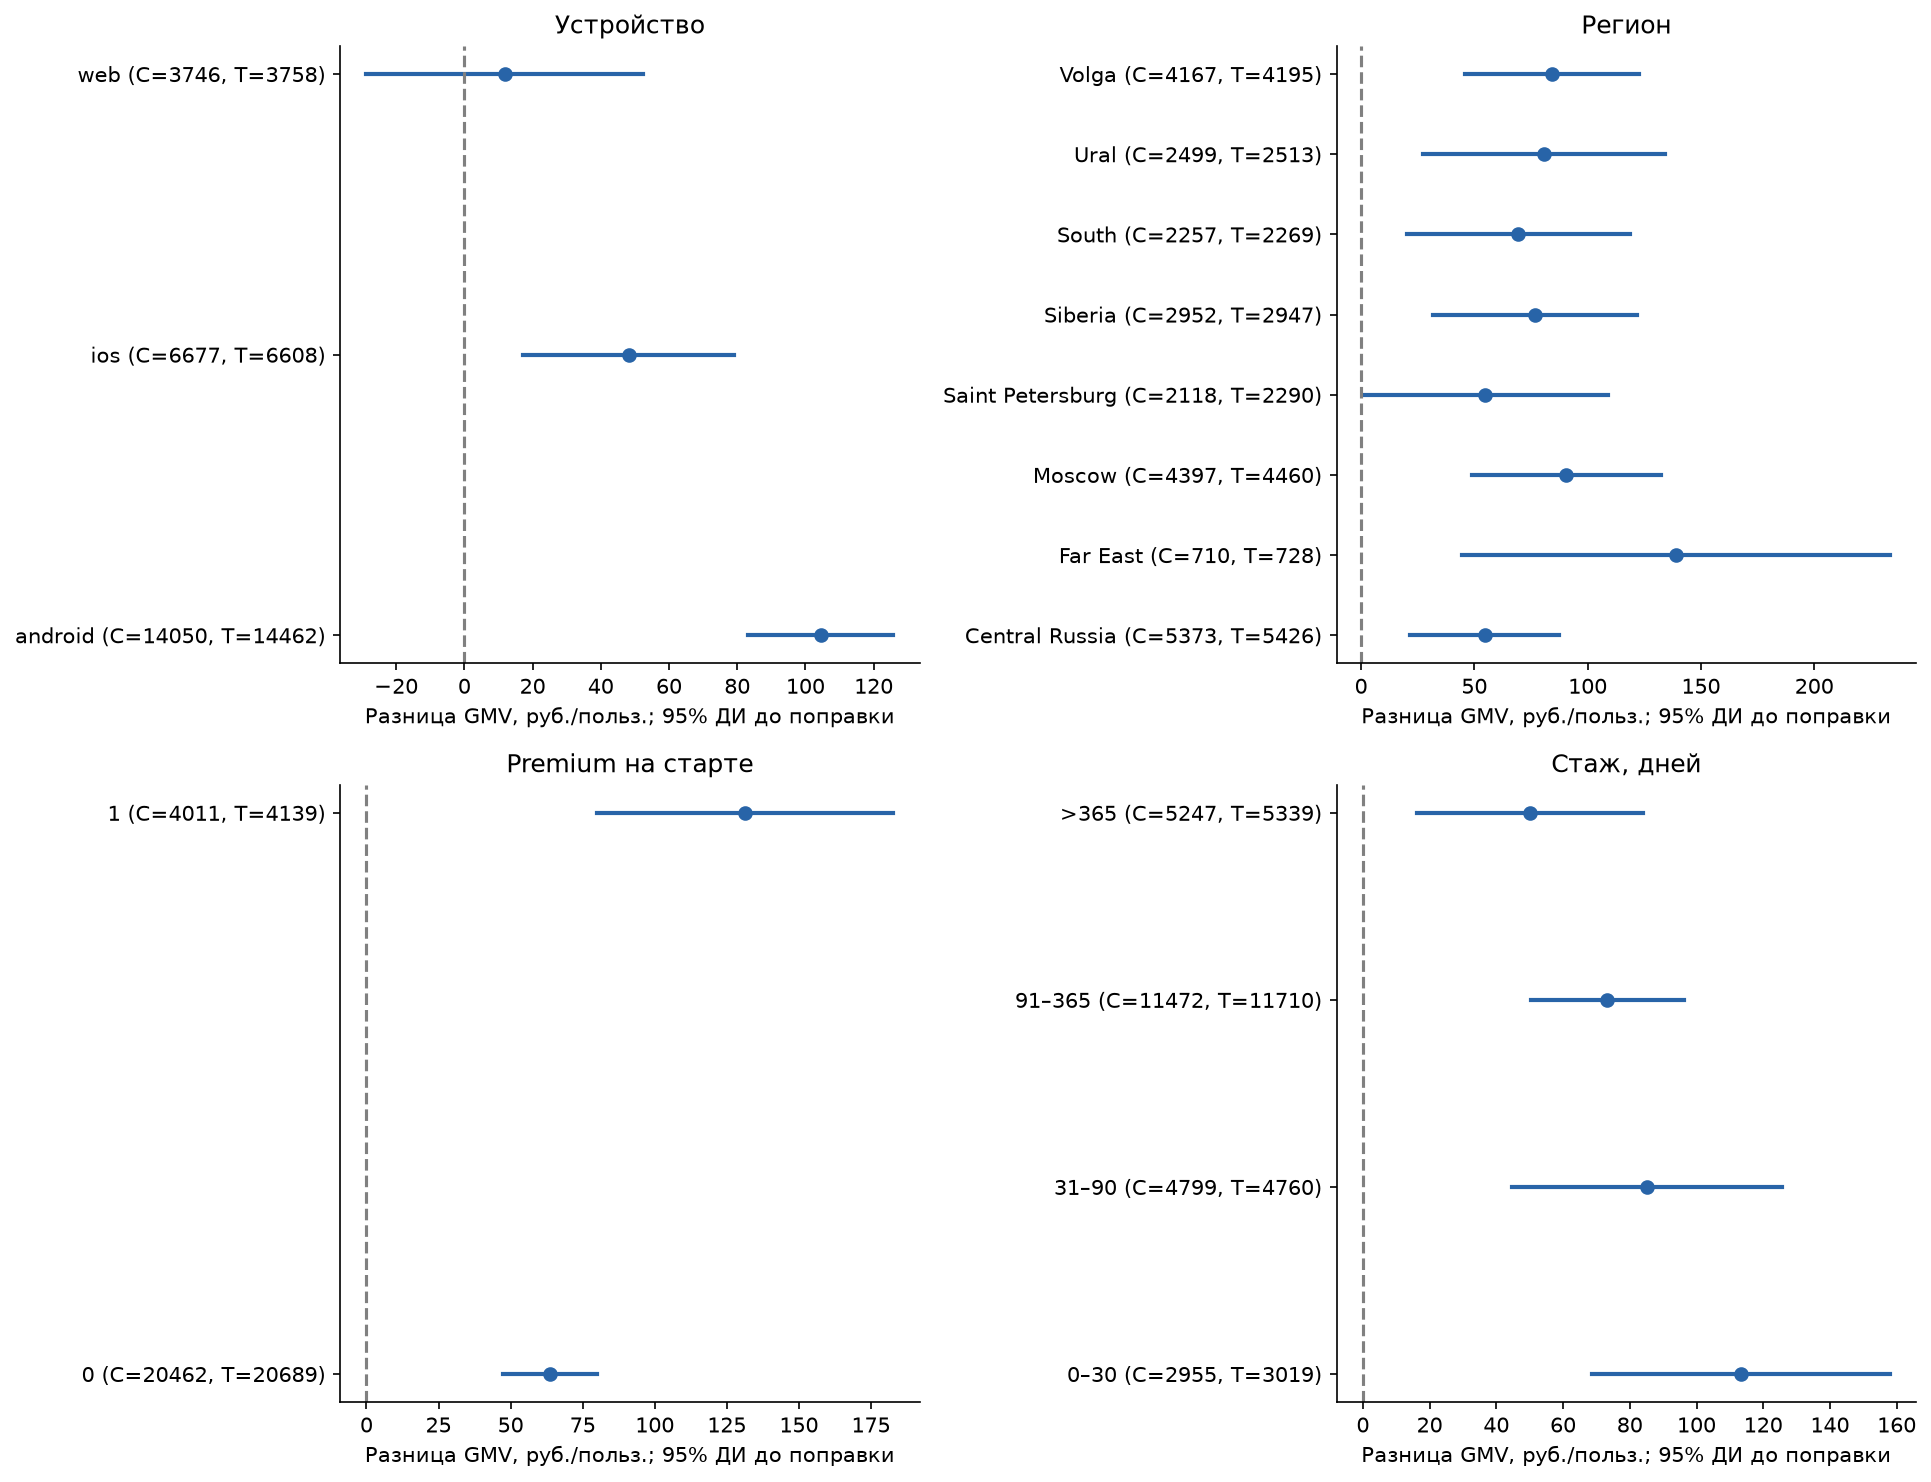

**07_categories**

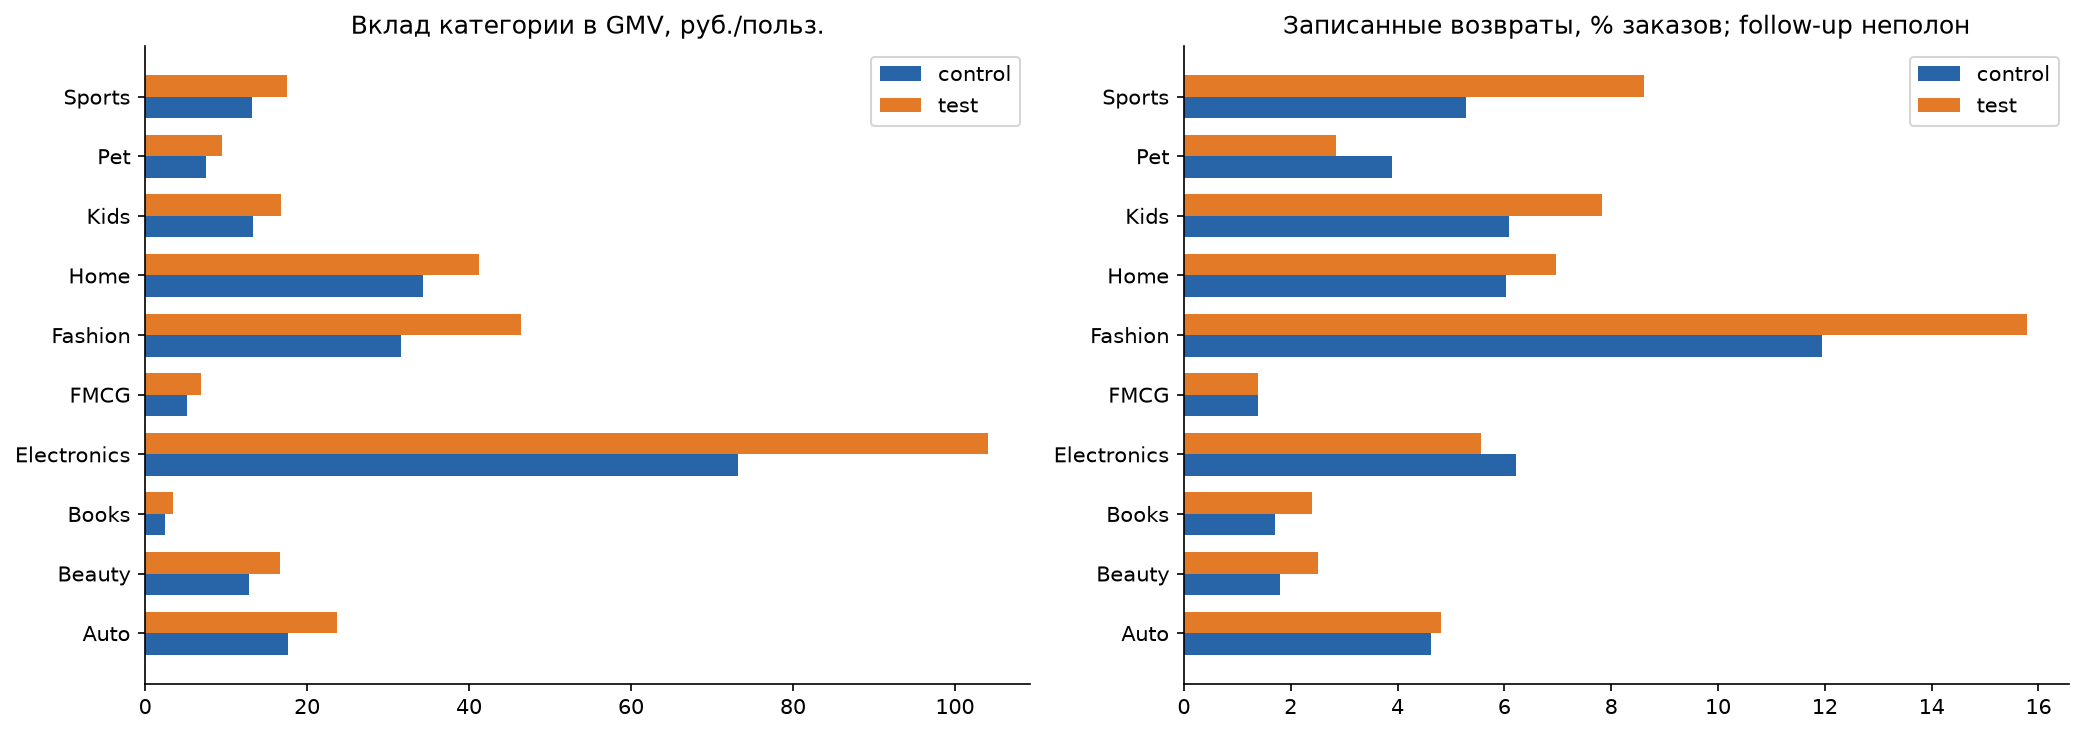

**08_support_returns**

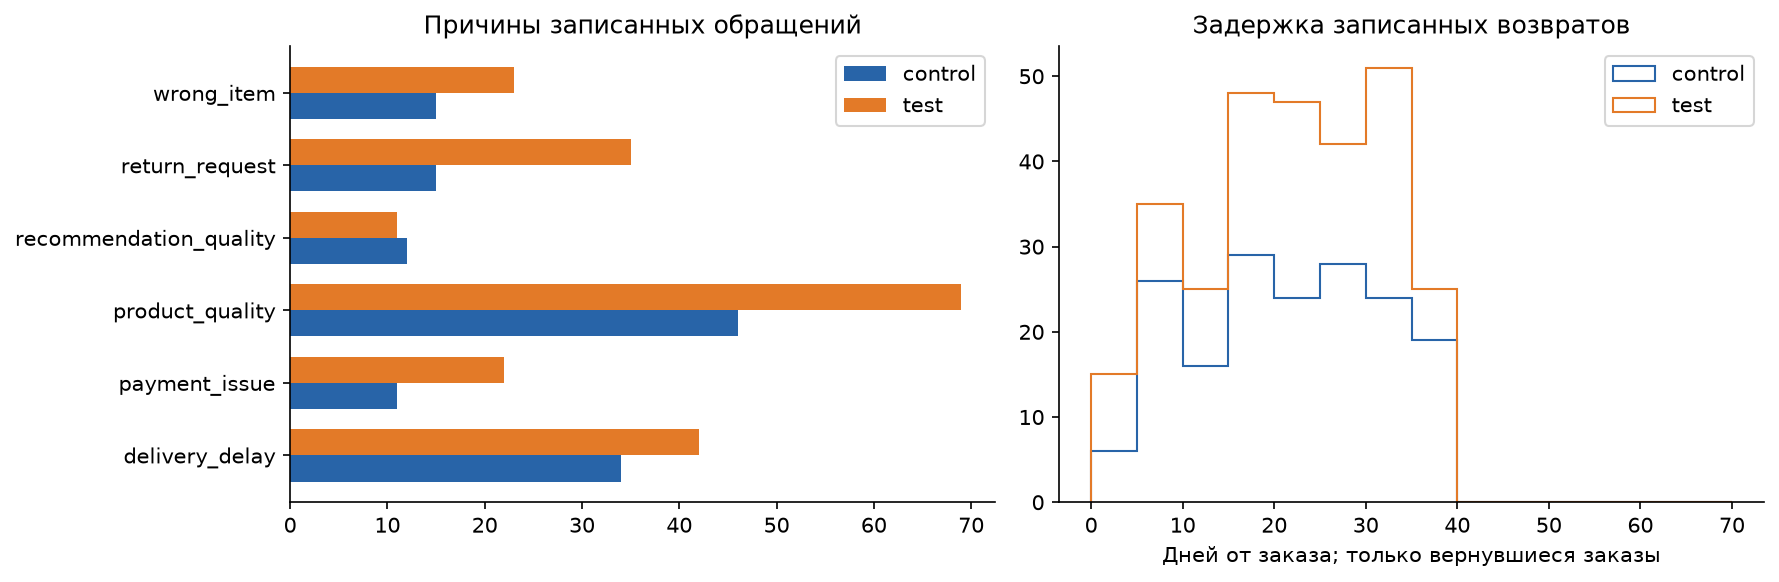

**09_economic_scenarios**

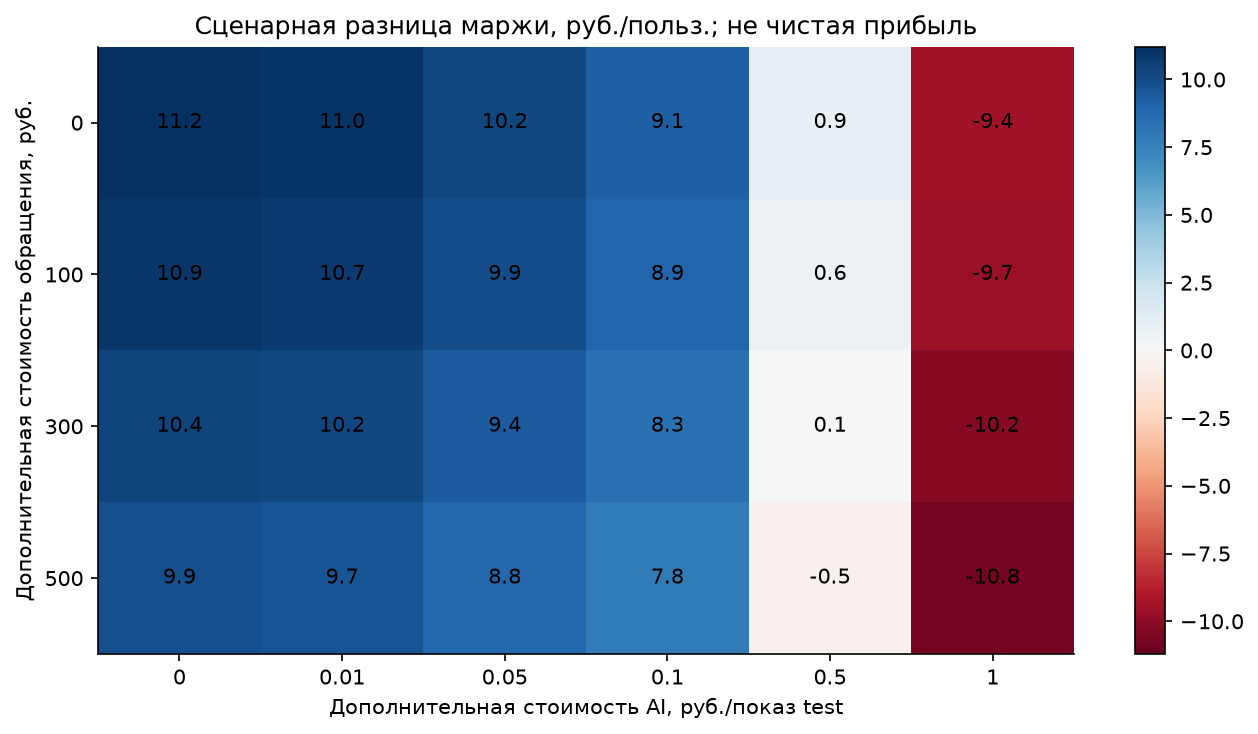

In [10]:
for path in result['figures']:
    display(Markdown(f'**{path.stem}**'))
    display(Image(filename=str(path)))

In [11]:
# Отчёт содержит ограничения, пороги и интерпретации графиков.
display(Markdown(result['report'].read_text(encoding='utf-8').split('## Графики')[0]))

# Результат A/B-эксперимента AI-рекомендаций

Рост основной метрики подтверждается в выбранной выборке. Решение о запуске условно: необходимо проверить допустимый вред и неизвестные расходы.

Бизнес-пороги и расходы заданы не полностью; безусловное разрешение на запуск не формируется.

## Основные результаты

Основная выборка: control — 24,473, test — 24,828 пользователей.
GMV/user: control 211.15 руб., test 286.41 руб.; разница 75.27 руб.
(35.65%), 95% ДИ [59.15; 91.39], p после Holm = 2.339e-19.
Записанная маржа/user: разница 11.21 руб., 95% ДИ [8.63; 13.79].
Это валовая маржа с записанными возвратами, не чистая прибыль и не маржа на дату 30 июля.

| label | effect_display | ci_display | p_adjusted | method |
| --- | --- | --- | --- | --- |
| GMV на пользователя | 75.268 руб./польз. | [59.147; 91.389] | 2.339e-19 | Welch t-test |
| Записанная валовая маржа на пользователя | 11.209 руб./польз. | [8.626; 13.792] | 5.571e-17 | Welch t-test |
| Доля пользователей с обращением в эксперименте | 0.279 п.п. | [0.141; 0.420] п.п. | 0.0001641 | Two-proportion Z-test; Newcombe CI |
| Конверсия пользователя в покупку | 3.363 п.п. | [2.761; 3.966] п.п. | 3.248e-27 | Two-proportion Z-test; Newcombe CI |
| CTR уникальных записей показов | 1.719 п.п. | [1.612; 1.825] п.п. | 9.649e-217 | User-cluster delta method |
| Возвраты в эксперименте / заказы | 0.350 п.п. | [-0.328; 1.029] п.п. | 0.3888 | User-cluster delta method |
| Записанные возвраты / заказы | 1.289 п.п. | [0.182; 2.395] п.п. | 0.03744 | User-cluster delta method |
| Записанные обращения на заказ | 0.005 на пользователя | [-0.005; 0.015] | 0.3888 | User-cluster delta method |

Интервалы в таблице — индивидуальные, до поправки. Подтверждающее семейство Holm:
GMV/user, маржа/user, доли пользователей с возвратом и обращением внутри эксперимента.
Вторичные проверки имеют отдельную FDR-поправку. p-value не измеряет размер бизнес-выигрыша.

## Ограничения по вреду

- Доля пользователей с возвратом в эксперименте: эффект 0.145 п.п.; верхняя граница 0.248 п.п.; Порог не задан — безопасность не установлена.
- Доля пользователей с обращением в эксперименте: эффект 0.279 п.п.; верхняя граница 0.420 п.п.; Порог не задан — безопасность не установлена.

Верхние 97.5% границы для двух guardrail соответствуют односторонней поправке Bonferroni;
незначимое ухудшение само по себе не подтверждает безопасность.
Возвраты на заказ и обращения на заказ оцениваются с кластеризацией по пользователю.

## Данные и допущения

- Окно заказов и основного воздействия: 2026-07-01 — 2026-07-30, включительно.
- Рандомизация предполагается по user_id; ожидаемые группы 50%/50% — допущение.
- Исключены конфликты назначения и is_bot_candidate=1. Выборка после исключений не является полным ITT;
  фильтрация может влиять на причинную интерпретацию. Первичное назначение и включение ботов — чувствительность.
- Временная точность назначения — день. Для первичного назначения предполагается старт в начале дня;
  причинный ITT для конфликтующих пользователей требует подтверждения журнала рандомизации.
- Нули неактивных пользователей основаны на допущении о полноте журнала событий.
- Флаги дублей имеют самостоятельные ID и связанные клики: уникальные события сохранены;
  CTR без флага вынесен в чувствительность. Восстановимого оригинала по естественному ключу нет.
- Дата полной выгрузки: неизвестна. Последнее событие не доказывает полноту follow-up.
  Записанные поздние возвраты описательны; без даты выгрузки нет сопоставимого подтверждённого 30-дневного окна после каждого заказа.
- gross_margin_rub уже отражает возвраты; повторное вычитание возвратов не применяется.
- delivery_fee_rub не заполняется для основной метрики. Суммы доставки со сценарными заполнениями
  сохранены отдельно; экономический знак и включение доставки в маржу не установлены.
- Стоимость возвращённых заказов не объявляется суммой возмещения. Условный net GMV включается только отдельной настройкой.

## Сегменты и чувствительность

После FDR обнаружены взаимодействия: device/gmv_user, device/margin_user, device/support_user_window, is_premium/gmv_user, is_premium/margin_user
Сегменты исследовательские. Для ограниченного запуска нужны воспроизводимость эффекта,
допустимый вред и подтверждающий эксперимент в выбранном исходном сегменте.
Категории — вклад исходов на всей аудитории; покупатели категории не объявляются исходным сегментом.

Чувствительность: включение ботов, первичное назначение, CTR без помеченных показов,
верхняя отсечка GMV/маржи на общей 99-й перцентили. Усечённая метрика имеет другую гипотезу.
Bootstrap: 2000 повторений, seed 2026; KS: 1999 перестановок.
Для KS используются перестановки пользовательских меток из-за нулей и совпадений.
MDE — нормальное приближение чувствительности при мощности 80%; для редких событий
и небольших сегментов требует отдельного планирования. Наблюдаемая мощность не рассчитывается.

## Экономика и следующий шаг

Сценарий = записанная маржа − дополнительная стоимость записанных обращений
− стоимость AI-показов в test. Учитывается предположение, что эти расходы ещё не включены в маржу.
Расходы доставки, возвраты и подписная выручка повторно не добавляются.
Результат не включает все расходы бизнеса и поэтому не является чистой прибылью.

Предельная дополнительная цена AI-показа, при которой сценарная разница маржи
равна нулю (руб./показ test; интервалы дельта-метода):

| support_cost_rub | ai_break_even_rub_per_impression | ci_low | ci_high |
| --- | --- | --- | --- |
| 0 | 0.5435 | 0.4187 | 0.6682 |
| 100 | 0.5304 | 0.4063 | 0.6544 |
| 300 | 0.5042 | 0.3804 | 0.6279 |
| 500 | 0.478 | 0.3528 | 0.6031 |

При цене выше точечной границы ожидаемый сценарный выигрыш становится отрицательным;
нижняя граница интервала показывает более консервативный ориентир с учётом неопределённости.

Перед решением задать минимально полезный рост и допустимое ухудшение в п.п.,
подтвердить полноту последующего наблюдения, состав gross_margin_rub и стоимость AI/поддержки.
Для сегментного запуска повторить эксперимент в заранее выбранном сегменте.
Один синтетический эксперимент не доказывает долгосрочный эффект, удержание или LTV.

